# ML from Scratch - 3 - KNN

## Importing

In [22]:
import importlib
import my_knn

importlib.reload(my_knn)
from my_knn import KNN

## Synthetic Data

In [23]:
import numpy as np

np.random.seed(42)

X = np.random.randn(100, 5)

rng = np.random.default_rng(seed=42)

y = rng.choice([0, 1, 2], size=100)

y

array([0, 2, 1, 1, 1, 2, 0, 2, 0, 0, 1, 2, 2, 2, 2, 2, 1, 0, 2, 1, 1, 1,
       0, 2, 2, 1, 1, 2, 1, 1, 1, 0, 0, 1, 2, 0, 2, 2, 0, 1, 0, 2, 2, 1,
       0, 2, 1, 2, 2, 2, 2, 0, 1, 1, 1, 0, 1, 0, 2, 2, 2, 2, 1, 2, 1, 0,
       2, 1, 0, 1, 2, 0, 1, 0, 2, 1, 0, 0, 1, 2, 2, 1, 0, 2, 1, 2, 0, 0,
       2, 2, 1, 2, 2, 1, 2, 0, 0, 2, 1, 0])

In [24]:
model_3n = KNN(n_neighbors=3)

model_3n.fit(X[:80], y[:80])

In [25]:
from sklearn.metrics import accuracy_score

y_pred = model_3n.predict(X[80:])

accuracy_score(y[80:], y_pred)

0.3

## Iris

In [26]:
import pandas as pd

train_df = pd.read_csv('../data/iris/train.csv')

train_df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,2.5,3.0,1.1,versicolor
1,6.2,2.2,4.5,1.5,versicolor
2,5.1,3.8,1.5,0.3,setosa
3,6.8,3.2,5.9,2.3,virginica
4,5.7,2.8,4.1,1.3,versicolor


### EDA

In [27]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  105 non-null    float64
 1   sepal_width   105 non-null    float64
 2   petal_length  105 non-null    float64
 3   petal_width   105 non-null    float64
 4   species       105 non-null    object 
dtypes: float64(4), object(1)
memory usage: 4.2+ KB


In [28]:
train_df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,105.000000,105.000000,105.000000,105.000000
mean,5.873333,3.055238,3.784762,1.205714
std,0.862941,0.457203,1.784052,0.777549
min,4.300000,2.000000,1.100000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.200000,1.300000
75%,6.400000,3.300000,5.100000,1.900000
max,7.900000,4.400000,6.900000,2.500000


In [29]:
setosa = train_df[train_df['species'] == 'setosa']
versicolor = train_df[train_df['species'] == 'versicolor']
virginica = train_df[train_df['species'] == 'virginica']

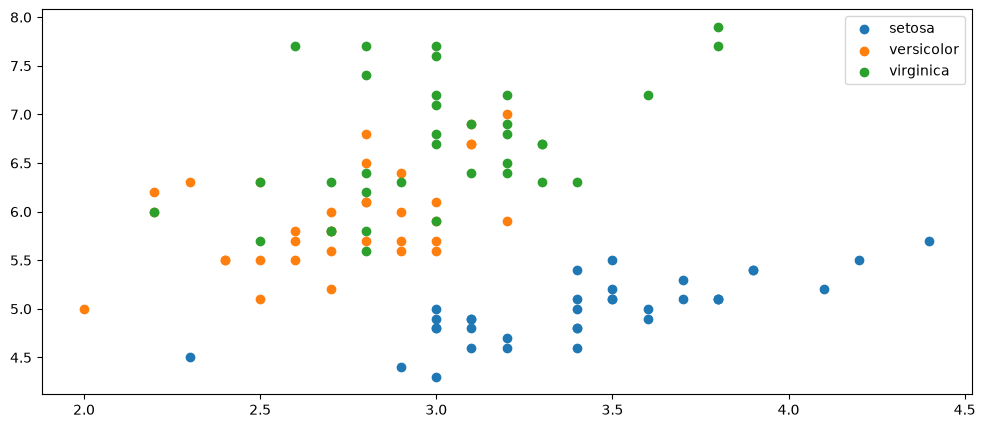

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.scatter(setosa['sepal_width'], setosa['sepal_length'], label='setosa')
plt.scatter(versicolor['sepal_width'], versicolor['sepal_length'], label='versicolor')
plt.scatter(virginica['sepal_width'], virginica['sepal_length'], label='virginica')

plt.legend()
plt.show()

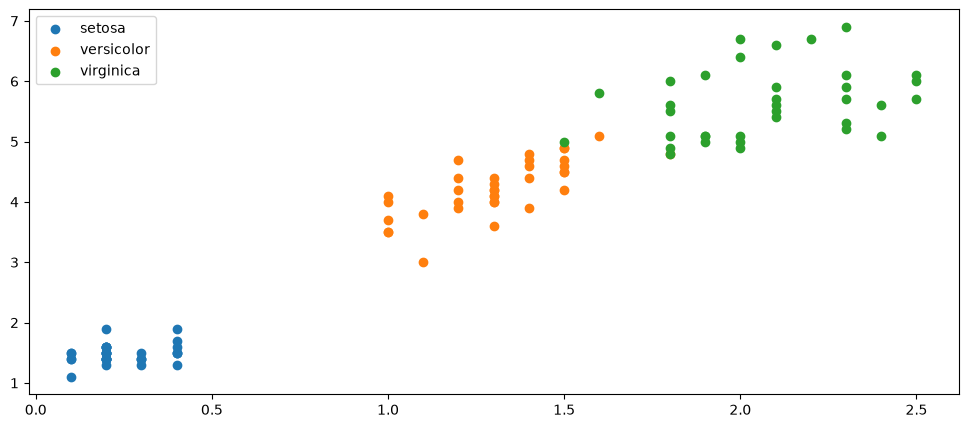

In [31]:
plt.figure(figsize=(12,5))

plt.scatter(setosa['petal_width'], setosa['petal_length'], label='setosa')
plt.scatter(versicolor['petal_width'], versicolor['petal_length'], label='versicolor')
plt.scatter(virginica['petal_width'], virginica['petal_length'], label='virginica')

plt.legend()
plt.show()

### Preprocessing

In [32]:
target = 'species'

X = train_df.drop(target, axis=1)
y = train_df[target]

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

X_train.shape, X_val.shape

((84, 4), (21, 4))

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_preprocessed = scaler.fit_transform(X_train)
X_val_preprocessed = scaler.transform(X_val)
X_full_preprocessed = scaler.transform(X)

### Model Training

#### My Model (k = 3)

In [35]:
model_3n = KNN(n_neighbors=3)

model_3n.fit(X_train_preprocessed, y_train)

In [36]:
y_pred_3n = model_3n.predict(X_val_preprocessed)

accuracy_score(y_val, y_pred_3n)

0.9523809523809523

#### My Model (k = 5)

In [37]:
model_5n = KNN(n_neighbors=5)

model_5n.fit(X_train_preprocessed, y_train)

In [38]:
y_pred_5n = model_5n.predict(X_val_preprocessed)

accuracy_score(y_val, y_pred_5n)

1.0

#### My Model (k = 10)

In [39]:
model_10n = KNN(n_neighbors=10)

model_10n.fit(X_train_preprocessed, y_train)

In [40]:
y_pred_10n = model_10n.predict(X_val_preprocessed)

accuracy_score(y_val, y_pred_10n)

1.0

#### SciKit-Learn Model

In [48]:
from sklearn.neighbors import KNeighborsClassifier

model_sklearn = KNeighborsClassifier(n_neighbors=10)
model_sklearn.fit(X_train_preprocessed, y_train)

,n_neighbors,10
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [49]:
y_pred_sklearn = model_sklearn.predict(X_val_preprocessed)

accuracy_score(y_val, y_pred_sklearn)

1.0

### Retraining and Submission

In [43]:
model_10n.fit(X_full_preprocessed, y)
model_sklearn.fit(X_full_preprocessed, y)

,n_neighbors,10
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [51]:
test_df = pd.read_csv('../data/iris/test.csv').set_index('id')

test_df.head()

,sepal_length,sepal_width,petal_length,petal_width
id,,,,
0,7.3,2.9,6.3,1.8
1,6.1,2.9,4.7,1.4
2,6.3,2.8,5.1,1.5
3,6.3,3.3,4.7,1.6
4,6.1,3.0,4.9,1.8


In [52]:
X_test_preprocessed = scaler.transform(test_df)

In [59]:
y_test_10n = model_10n.predict(X_test_preprocessed)

submission_10n = pd.DataFrame(y_test_10n, columns=['species'], index=test_df.index)

submission_10n.to_csv('../data/iris/submissions/submission_knn_10n.csv', sep=',')

In [60]:
y_test_sklearn = model_sklearn.predict(X_test_preprocessed)

submission_sklearn = pd.DataFrame(y_test_sklearn, columns=['species'], index=test_df.index)

submission_sklearn.to_csv('../data/iris/submissions/submission_knn_sklearn.csv', sep=',')

Kaggle Score for my model (k = 10): `0.94444`

Kaggle Score for SciKit-Learn model: `0.94444`